In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings("ignore")

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc
)

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [7]:
df = pd.read_csv("household_power_consumption.txt", sep=";", na_values=["?"], low_memory=False)
print(f"Raw shape: {df.shape}")

Raw shape: (295208, 9)


In [8]:
df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"],
                                format="%d/%m/%Y %H:%M:%S", errors="coerce")
df.drop(columns=["Date", "Time"], inplace=True)

In [9]:
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df.dropna(subset=["Datetime"], inplace=True)

In [10]:
np.random.seed(42)
df["Hour"] = df["Datetime"].dt.hour
df["Month"] = df["Datetime"].dt.month

In [11]:
df["Temperature"] = (
    20 + 8 * np.sin(2 * np.pi * (df["Hour"] - 6) / 24)
    + 4 * np.sin(2 * np.pi * df["Month"] / 12)
    + np.random.normal(0, 2, len(df))
)

In [12]:
df["Humidity"] = (
    55 - 8 * np.sin(2 * np.pi * df["Hour"] / 24)
    + np.random.normal(0, 6, len(df))
).clip(20, 95)


In [13]:
df["Sub_Metering_Total"] = (
    df["Sub_metering_1"] + df["Sub_metering_2"] + df["Sub_metering_3"]
)


In [14]:
df["Light_Availability"] = (df["Hour"].between(7, 19)).astype(int)
df["Voltage"]          = pd.to_numeric(df["Voltage"], errors="coerce").fillna(230)
df["Global_Intensity"] = pd.to_numeric(df["Global_intensity"], errors="coerce").fillna(0)

In [15]:
df["Global_active_power"] = pd.to_numeric(df["Global_active_power"], errors="coerce")
df["Global_active_power"].fillna(df["Global_active_power"].median(), inplace=True)

In [16]:
p40 = df["Global_active_power"].quantile(0.40)
p60 = df["Global_active_power"].quantile(0.60)
median = df["Global_active_power"].median()


In [17]:
df["Power_Status"] = (df["Global_active_power"] > median).astype(int)


In [18]:
band = df["Global_active_power"].between(p40, p60)
flip_idx = df[band].sample(frac=0.55, random_state=99).index
df.loc[flip_idx, "Power_Status"] = 1 - df.loc[flip_idx, "Power_Status"]

In [19]:
print(f"Median threshold : {median:.4f} kW")
print(f"Class distribution:\n{df['Power_Status'].value_counts()}")

Median threshold : 0.6100 kW
Class distribution:
Power_Status
1    147726
0    147482
Name: count, dtype: int64


In [20]:
FEATURES = ["Temperature", "Humidity", "Hour",
            "Voltage", "Global_Intensity",
            "Sub_Metering_Total", "Light_Availability"]


In [21]:
X = df[FEATURES]
y = df["Power_Status"]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [23]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [24]:
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
print("Scaler saved → scaler.pkl")

Scaler saved → scaler.pkl


In [25]:
tf.random.set_seed(42)

In [26]:
model = Sequential([
    Dense(16, activation="relu", input_shape=(7,)),
    Dropout(0.2),
    Dense(8,  activation="relu"),
    Dense(1,  activation="sigmoid")
])

In [27]:
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
early_stop = EarlyStopping(monitor="val_loss", patience=8,
                           restore_best_weights=True, verbose=1)

In [29]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=80,
    batch_size=1024,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.7808 - loss: 0.4952 - val_accuracy: 0.8934 - val_loss: 0.2986
Epoch 2/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8877 - loss: 0.2954 - val_accuracy: 0.8941 - val_loss: 0.2565
Epoch 3/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8915 - loss: 0.2711 - val_accuracy: 0.8929 - val_loss: 0.2463
Epoch 4/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8922 - loss: 0.2610 - val_accuracy: 0.8925 - val_loss: 0.2400
Epoch 5/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8922 - loss: 0.2516 - val_accuracy: 0.8916 - val_loss: 0.2320
Epoch 6/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8918 - loss: 0.2417 - val_accuracy: 0.8912 - val_loss: 0.2219
Epoch 7/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8919 - loss: 0.2302 - val_accuracy: 0.8914 - val_loss: 0.2114
Epoch 8/80
185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8923 - loss: 0.2192 - val_accuracy: 

In [30]:
model.save("model.h5")
print("Model saved → model.h5")

Model saved → model.h5


In [31]:
y_prob = model.predict(X_test).flatten()
y_pred = (y_prob >= 0.5).astype(int)

1846/1846 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [32]:
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)

In [33]:
print("\n========================================")
print(f"  Accuracy  : {acc:.4f}")
print(f"  Precision : {prec:.4f}")
print(f"  Recall    : {rec:.4f}")
print(f"  F1 Score  : {f1:.4f}")
print("========================================")
print(classification_report(y_test, y_pred, target_names=["LOW (OFF)", "HIGH (ON)"]))


  Accuracy  : 0.8974
  Precision : 0.9795
  Recall    : 0.8119
  F1 Score  : 0.8878
              precision    recall  f1-score   support

   LOW (OFF)       0.84      0.98      0.91     29497
   HIGH (ON)       0.98      0.81      0.89     29545

    accuracy                           0.90     59042
   macro avg       0.91      0.90      0.90     59042
weighted avg       0.91      0.90      0.90     59042



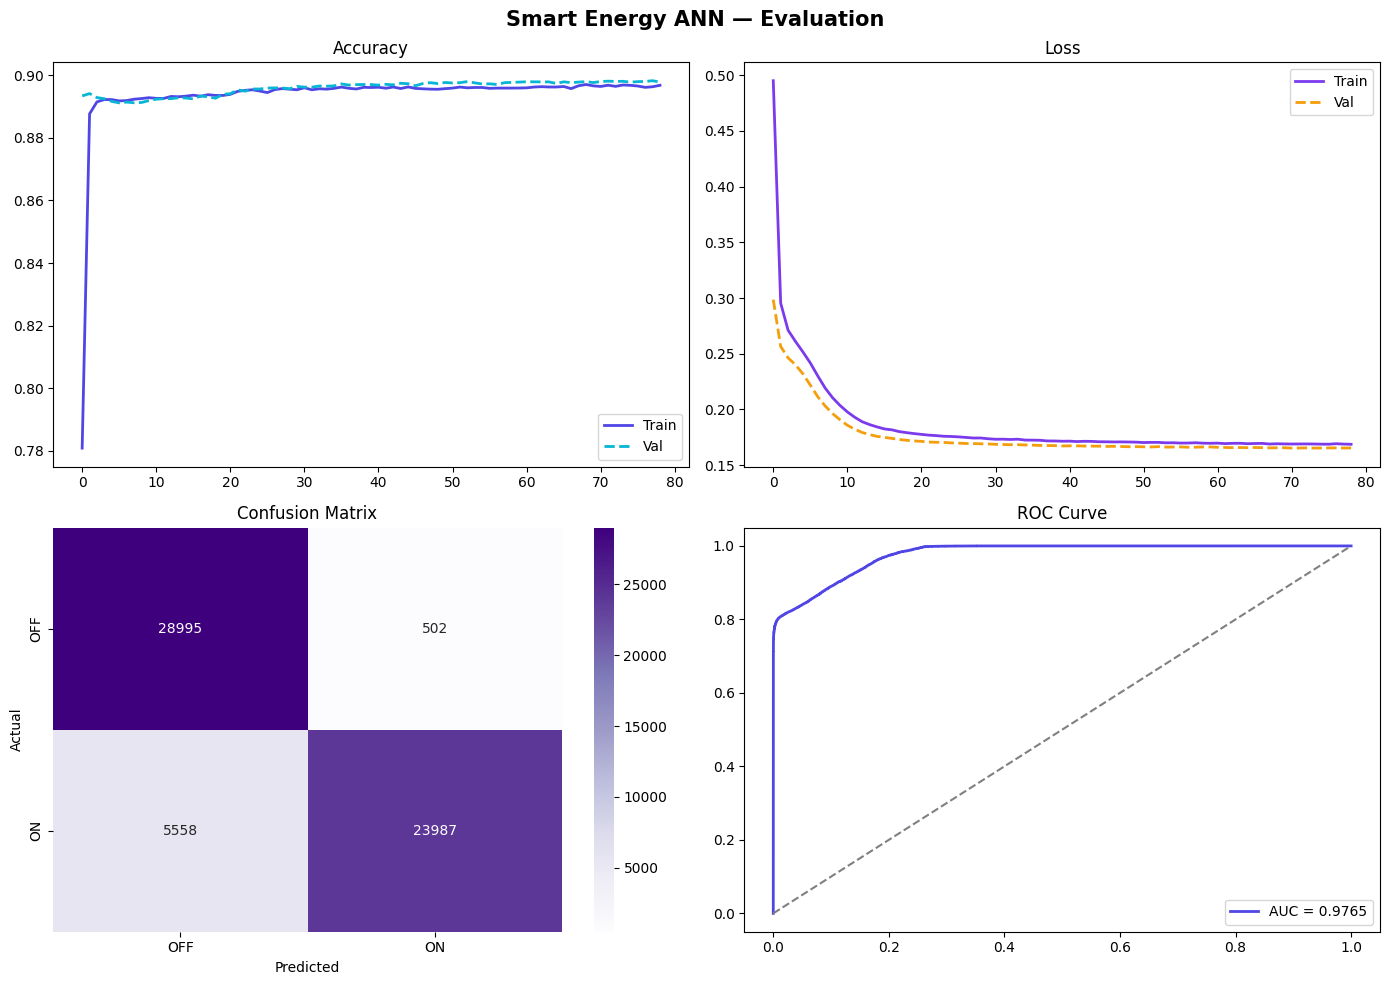

Plots saved → evaluation_plots.png


In [34]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Smart Energy ANN — Evaluation", fontsize=15, fontweight="bold")

# Accuracy curve
axes[0,0].plot(history.history["accuracy"],     label="Train", color="#4f46e5", lw=2)
axes[0,0].plot(history.history["val_accuracy"], label="Val",   color="#06b6d4", lw=2, ls="--")
axes[0,0].set_title("Accuracy"); axes[0,0].legend()

# Loss curve
axes[0,1].plot(history.history["loss"],     label="Train", color="#7c3aed", lw=2)
axes[0,1].plot(history.history["val_loss"], label="Val",   color="#f59e0b", lw=2, ls="--")
axes[0,1].set_title("Loss"); axes[0,1].legend()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", ax=axes[1,0],
            xticklabels=["OFF","ON"], yticklabels=["OFF","ON"])
axes[1,0].set_title("Confusion Matrix")
axes[1,0].set_xlabel("Predicted"); axes[1,0].set_ylabel("Actual")
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
axes[1,1].plot(fpr, tpr, color="#4f46e5", lw=2, label=f"AUC = {roc_auc:.4f}")
axes[1,1].plot([0,1],[0,1], color="gray", ls="--")
axes[1,1].set_title("ROC Curve"); axes[1,1].legend()
plt.tight_layout()
plt.savefig("evaluation_plots.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plots saved → evaluation_plots.png")

In [35]:
import os

print(os.listdir('/content'))

['.config', 'evaluation_plots.png', 'model.h5', 'household_power_consumption.txt', 'scaler.pkl', 'sample_data']


In [36]:
%cd /content
!git clone https://github.com/Harshsingh904/Smart-Home-Energy-Management-System.git

/content
Cloning into 'Smart-Home-Energy-Management-System'...


In [37]:
%cd /content/Smart-Home-Energy-Management-System

/content/Smart-Home-Energy-Management-System


In [38]:
!cp /content/model.h5 .
!cp /content/scaler.pkl .
!cp /content/household_power_consumption.txt .
!cp /content/evaluation_plots.png .

In [39]:
!git config user.name "Harshsingh904"
!git config user.email "hardieeharsh1212144@gmail.com"

In [40]:
!git add model.h5 scaler.pkl household_power_consumption.txt evaluation_plots.png
!git status

On branch main

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   evaluation_plots.png
	new file:   household_power_consumption.txt
	new file:   model.h5
	new file:   scaler.pkl



In [41]:
!git commit -m "Add Smart Home Energy Management System files"

[main (root-commit) 2ac409f] Add Smart Home Energy Management System files
 4 files changed, 2075260 insertions(+)
 create mode 100644 evaluation_plots.png
 create mode 100644 household_power_consumption.txt
 create mode 100644 model.h5
 create mode 100644 scaler.pkl


In [42]:
!git push origin main

fatal: could not read Username for 'https://github.com': No such device or address
